# Wave-Swin-GNN: Bone Fracture Detection
## Hybrid Model: Wavelet Transform + Swin Transformer V2 + Graph Neural Network

**Architecture:**
- **Dual-Path Design** — Wavelet path (high-frequency features) + Swin path (semantic features), fused via GNN
- **GPU-Native Haar DWT** — Implemented via `F.conv2d` for full GPU utilization
- **SwinV2-Tiny** — Window size 8, pretrained, fine-tuned (layers 0-2 frozen)
- **KNN-Graph GATv2** — K=6 spatial graph with multi-head attention and residual connections

**Combined Dataset:** FracAtlas (~4,083 images) + Bone Fracture Multi-Region X-ray (~10,580 images) = ~14,663 total

**Target Metrics:** AP > 0.90, Recall > 80% at 85% precision, AUROC > 0.93, F1 > 0.85

In [4]:
# ==========================================
# CELL 1: SETUP & INSTALLATIONS
# ==========================================
import os
import gc
import random
import time
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch_geometric.nn import GATv2Conv
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import (
    confusion_matrix, roc_curve, auc, roc_auc_score,
    precision_recall_curve, average_precision_score,
    classification_report, accuracy_score,
    precision_score, recall_score, f1_score
)
from sklearn.model_selection import StratifiedShuffleSplit

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")
print(f"Random seed: {SEED}")

GPU: NVIDIA GeForce RTX 4060 Ti
Device: cuda
PyTorch: 2.10.0+cu128
Random seed: 42


## Cell 2: Combined Dataset Loader

Loads both **FracAtlas** and **Bone Fracture Multi-Region X-ray** datasets into a unified pipeline with:
- Dual image integrity verification (PIL + OpenCV)
- CLAHE preprocessing
- Albumentations augmentation
- Stratified 70/15/15 split by label AND source
- Weighted random sampling for class balance

In [5]:
# ==========================================
# CELL 2: COMBINED DATASET LOADER
# ==========================================

# ---- Configurable dataset paths ----
FRACATLAS_ROOT = "dataset/FracAtlas"
MULTIREGION_ROOT = "dataset/Bone_Fracture_Multi_Region"

# ---- Image verification ----
def verify_image(img_path):
    """Verify image integrity using both OpenCV and PIL."""
    try:
        img = cv2.imread(img_path)
        if img is None:
            return False
        with Image.open(img_path) as pil_img:
            pil_img.load()  # Force full decode, not just header check
        return True
    except:
        return False

# ---- Load FracAtlas ----
def load_fracatlas(root_dir):
    csv_path = os.path.join(root_dir, "dataset.csv")
    data = pd.read_csv(csv_path)
    entries = []
    corrupt_count = 0
    
    print("Loading FracAtlas...")
    for _, row in tqdm(data.iterrows(), total=len(data), desc="FracAtlas"):
        img_name = row.get('image_id')
        label = int(row.get('fractured', 0))
        subfolder = "Fractured" if label == 1 else "Non_fractured"
        img_path = os.path.join(root_dir, "images", subfolder, str(img_name))
        
        if not os.path.exists(img_path):
            continue
        if verify_image(img_path):
            entries.append({'path': img_path, 'label': float(label), 'source': 'fracatlas'})
        else:
            corrupt_count += 1
    
    print(f"  FracAtlas: {len(entries)} valid, {corrupt_count} corrupt removed")
    return entries, corrupt_count

# ---- Load Bone Fracture Multi-Region ----
def load_multiregion(root_dir):
    entries = []
    corrupt_count = 0
    
    print("Loading Bone Fracture Multi-Region...")
    for split in ['train', 'val', 'test']:
        split_dir = os.path.join(root_dir, split)
        if not os.path.isdir(split_dir):
            continue
        for class_folder in os.listdir(split_dir):
            class_path = os.path.join(split_dir, class_folder)
            if not os.path.isdir(class_path):
                continue
            label = 1.0 if 'fractured' in class_folder.lower() and 'not' not in class_folder.lower() else 0.0
            for img_file in os.listdir(class_path):
                img_path = os.path.join(class_path, img_file)
                if not img_file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp')):
                    continue
                if verify_image(img_path):
                    entries.append({'path': img_path, 'label': label, 'source': 'multiregion'})
                else:
                    corrupt_count += 1
    
    print(f"  Multi-Region: {len(entries)} valid, {corrupt_count} corrupt removed")
    return entries, corrupt_count

# ---- Load both datasets ----
fracatlas_data, fa_corrupt = load_fracatlas(FRACATLAS_ROOT)
multiregion_data, mr_corrupt = load_multiregion(MULTIREGION_ROOT)
all_data = fracatlas_data + multiregion_data

print(f"\n--- Combined Dataset Summary ---")
print(f"Total images: {len(all_data)}")
print(f"  FracAtlas: {len(fracatlas_data)} ({sum(1 for d in fracatlas_data if d['label']==1)} fractured)")
print(f"  Multi-Region: {len(multiregion_data)} ({sum(1 for d in multiregion_data if d['label']==1)} fractured)")
print(f"  Total fractured: {sum(1 for d in all_data if d['label']==1)}")
print(f"  Total non-fractured: {sum(1 for d in all_data if d['label']==0)}")
print(f"  Corrupt removed: {fa_corrupt + mr_corrupt} (FracAtlas: {fa_corrupt}, Multi-Region: {mr_corrupt})")

# ---- Stratified splitting by label AND source ----
labels = [int(d['label']) for d in all_data]
sources = [d['source'] for d in all_data]
# Create combined stratification key
strat_key = [f"{l}_{s}" for l, s in zip(labels, sources)]

# First split: 70% train, 30% temp
splitter1 = StratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, temp_idx = next(splitter1.split(all_data, strat_key))

# Second split: 50/50 of temp -> 15% val, 15% test
temp_strat = [strat_key[i] for i in temp_idx]
splitter2 = StratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_rel_idx, test_rel_idx = next(splitter2.split(temp_idx, temp_strat))
val_idx = temp_idx[val_rel_idx]
test_idx = temp_idx[test_rel_idx]

train_data = [all_data[i] for i in train_idx]
val_data = [all_data[i] for i in val_idx]
test_data = [all_data[i] for i in test_idx]

print(f"\n--- Split Summary ---")
for name, split in [('Train', train_data), ('Val', val_data), ('Test', test_data)]:
    n_frac = sum(1 for d in split if d['label'] == 1)
    n_fa = sum(1 for d in split if d['source'] == 'fracatlas')
    print(f"  {name}: {len(split)} images ({n_frac} fractured, {len(split)-n_frac} non-fractured, {n_fa} FracAtlas, {len(split)-n_fa} Multi-Region)")

# ---- Augmentation transforms ----
# IMG_SIZE=256 to match swinv2_tiny_window8_256 expected input
IMG_SIZE = 256

train_transforms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.2),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.15, rotate_limit=30, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.GaussianBlur(p=0.2),
    A.CoarseDropout(max_holes=6, max_height=24, max_width=24, p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

val_transforms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

# ---- Dataset class ----
class BoneFractureDataset(Dataset):
    def __init__(self, data_list, transform=None):
        self.data = data_list
        self.transform = transform
    
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        entry = self.data[idx]
        image = cv2.imread(entry['path'])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        # CLAHE preprocessing
        lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
        l = clahe.apply(l)
        image = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2RGB)
        
        if self.transform:
            image = self.transform(image=image)['image']
        
        label = torch.tensor(entry['label'], dtype=torch.float32)
        return image, label

# ---- Create datasets ----
train_ds = BoneFractureDataset(train_data, train_transforms)
val_ds = BoneFractureDataset(val_data, val_transforms)
test_ds = BoneFractureDataset(test_data, val_transforms)

# ---- Weighted Random Sampler for training ----
train_labels = [int(d['label']) for d in train_data]
class_counts = [train_labels.count(0), train_labels.count(1)]
weights = [1.0 / class_counts[l] for l in train_labels]
sampler = WeightedRandomSampler(weights, len(weights))

# ---- DataLoaders (optimized for RTX 4060 Ti 8GB VRAM) ----
# Batch size 16 fits comfortably at 256x256 with mixed precision
# num_workers=2 is optimal for Windows (avoids multiprocessing overhead)
BATCH_SIZE = 16
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True, persistent_workers=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True, persistent_workers=True)

print(f"\nDataLoaders ready (Resolution: {IMG_SIZE}x{IMG_SIZE}, Batch size: {BATCH_SIZE})")
print(f"  Train batches: {len(train_loader)}, Val batches: {len(val_loader)}, Test batches: {len(test_loader)}")

Loading FracAtlas...


FracAtlas:   0%|          | 0/4083 [00:00<?, ?it/s]

Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
P

  FracAtlas: 4024 valid, 59 corrupt removed
Loading Bone Fracture Multi-Region...


Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
libpng warning: bKGD: invalid
libpng warning: bKGD: invalid
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: bKGD: invalid
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file


  Multi-Region: 10563 valid, 18 corrupt removed

--- Combined Dataset Summary ---
Total images: 14587
  FracAtlas: 4024 (717 fractured)
  Multi-Region: 10563 (5181 fractured)
  Total fractured: 5898
  Total non-fractured: 8689
  Corrupt removed: 77 (FracAtlas: 59, Multi-Region: 18)

--- Split Summary ---
  Train: 10210 images (4128 fractured, 6082 non-fractured, 2817 FracAtlas, 7393 Multi-Region)
  Val: 2188 images (885 fractured, 1303 non-fractured, 604 FracAtlas, 1584 Multi-Region)
  Test: 2189 images (885 fractured, 1304 non-fractured, 603 FracAtlas, 1586 Multi-Region)

DataLoaders ready (Resolution: 256x256, Batch size: 16)
  Train batches: 639, Val batches: 137, Test batches: 137


## Cell 3: Wave-Swin-GNN Model Architecture

**Dual-path design** that fixes the previous version's DWT→upsample anti-pattern:
- **Path A (Wavelet):** Input → DWT → 4 subbands (192x192) → Adapter → wavelet features
- **Path B (Original):** Input → SwinV2-Tiny → swin features → GNN → GNN features
- **Fusion:** Concatenate wavelet + GNN features → Classifier

In [6]:
# ==========================================
# CELL 3: WAVE-SWIN-GNN MODEL ARCHITECTURE
# ==========================================

class TorchDWT(nn.Module):
    """GPU-Native 2D Discrete Wavelet Transform (Haar Wavelet)."""
    def __init__(self):
        super().__init__()
        ll = torch.tensor([[1., 1.], [1., 1.]]) / 2.0
        lh = torch.tensor([[1., 1.], [-1., -1.]]) / 2.0
        hl = torch.tensor([[1., -1.], [1., -1.]]) / 2.0
        hh = torch.tensor([[1., -1.], [-1., 1.]]) / 2.0
        
        filters = torch.stack([ll, lh, hl, hh], dim=0).unsqueeze(1)  # (4, 1, 2, 2)
        self.register_buffer('filters', filters.repeat(3, 1, 1, 1))  # (12, 1, 2, 2)

    def forward(self, x):
        # x: (B, 3, H, W) -> (B, 12, H/2, W/2)
        return F.conv2d(x, self.filters, stride=2, groups=3)


class WaveletAdapter(nn.Module):
    """Adapts DWT output to a feature vector matching GNN output dimension."""
    def __init__(self, out_dim=256):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(12, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.GELU(),
            nn.Conv2d(64, 128, 3, padding=1, bias=False), nn.BatchNorm2d(128), nn.GELU(),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.proj = nn.Linear(128, out_dim)
    
    def forward(self, x):
        # x: (B, 12, H/2, W/2)
        x = self.conv(x)          # (B, 128, H/2, W/2)
        x = self.pool(x)          # (B, 128, 1, 1)
        x = x.flatten(1)          # (B, 128)
        return self.proj(x)       # (B, out_dim)


class WaveSwinGNN(nn.Module):
    def __init__(self, k=6, gnn_hidden=256, gnn_out=256):
        super().__init__()
        self.k = k
        
        # ---- Path A: Wavelet ----
        self.dwt = TorchDWT()
        self.wavelet_adapter = WaveletAdapter(out_dim=gnn_out)
        
        # ---- Path B: Swin Backbone ----
        self.swin = timm.create_model(
            'swinv2_tiny_window8_256', pretrained=True,
            num_classes=0, global_pool=''
        )
        self.feature_dim = self.swin.num_features  # 768 for tiny
        
        # Freeze layers 0-2, keep layer 3 and norms trainable
        for name, param in self.swin.named_parameters():
            if 'layers.0' in name or 'layers.1' in name or 'layers.2' in name:
                if 'norm' not in name:
                    param.requires_grad = False
        
        # ---- GNN Head ----
        self.gnn1 = GATv2Conv(self.feature_dim, gnn_hidden, heads=4, concat=True, dropout=0.2)
        self.gnn_norm1 = nn.LayerNorm(gnn_hidden * 4)
        self.gnn2 = GATv2Conv(gnn_hidden * 4, gnn_out, heads=1, concat=False, dropout=0.2)
        self.gnn_norm2 = nn.LayerNorm(gnn_out)
        
        # Residual projection for Swin features
        self.swin_proj = nn.Linear(self.feature_dim, gnn_out)
        
        # ---- Classifier (wavelet features + GNN features) ----
        self.classifier = nn.Sequential(
            nn.Linear(gnn_out + gnn_out, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )
    
    def build_knn_graph(self, num_nodes, batch_size, device):
        N = num_nodes // batch_size
        side = int(np.sqrt(N))
        if side * side < N:
            side += 1
        
        coords = torch.stack(
            torch.meshgrid(torch.arange(side), torch.arange(side), indexing='ij'), dim=-1
        ).float().reshape(-1, 2)[:N].to(device)
        
        dist = torch.cdist(coords, coords)
        _, topk = torch.topk(dist, k=min(self.k, N), largest=False)
        
        edge_indices = []
        for b in range(batch_size):
            offset = b * N
            src = torch.arange(N, device=device).view(-1, 1).expand(-1, min(self.k, N)).reshape(-1) + offset
            dst = topk.reshape(-1) + offset
            edge_indices.append(torch.stack([src, dst], dim=0))
        
        return torch.cat(edge_indices, dim=1)
    
    def forward(self, x):
        B = x.shape[0]
        
        # ---- Path A: Wavelet ----
        wavelet_sub = self.dwt(x)                    # (B, 12, 192, 192)
        wavelet_feat = self.wavelet_adapter(wavelet_sub)  # (B, 256)
        
        # ---- Path B: Swin + GNN ----
        swin_out = self.swin(x)                      # (B, H, W, C) or (B, N, C)
        if swin_out.dim() == 4:
            swin_out = swin_out.reshape(B, -1, self.feature_dim)
        N = swin_out.shape[1]
        
        # Swin pooled features for residual
        swin_pooled = swin_out.mean(dim=1)           # (B, feature_dim)
        swin_residual = self.swin_proj(swin_pooled)  # (B, 256)
        
        # GNN
        x_flat = swin_out.reshape(-1, self.feature_dim)  # (B*N, C)
        edge_index = self.build_knn_graph(x_flat.shape[0], B, x_flat.device)
        
        x_gnn = self.gnn1(x_flat, edge_index)
        x_gnn = self.gnn_norm1(x_gnn).relu()
        x_gnn = self.gnn2(x_gnn, edge_index)
        x_gnn = self.gnn_norm2(x_gnn).relu()
        
        # Global mean pooling + residual
        gnn_pooled = x_gnn.reshape(B, N, -1).mean(dim=1)  # (B, 256)
        gnn_feat = gnn_pooled + swin_residual              # (B, 256)
        
        # ---- Fusion ----
        fused = torch.cat([wavelet_feat, gnn_feat], dim=1)  # (B, 512)
        return self.classifier(fused)


model = WaveSwinGNN(k=6).to(device)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Wave-Swin-GNN initialized")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  Frozen parameters: {total_params - trainable_params:,}")

Wave-Swin-GNN initialized
  Total parameters: 30,059,947
  Trainable parameters: 17,883,985
  Frozen parameters: 12,175,962


## Cell 4: Training Loop

- Focal Loss (alpha=0.75, gamma=2.0)
- AdamW with lr=2e-5, weight_decay=0.05
- OneCycleLR scheduler (max_lr=1e-4)
- Mixed precision + gradient accumulation (effective batch size = 32)
- Early stopping (patience=10) on validation AP

In [7]:
# ==========================================
# CELL 4: TRAINING LOOP
# ==========================================

# Enable cuDNN autotuner for consistent input sizes (boosts speed on 4060 Ti)
torch.backends.cudnn.benchmark = True

class FocalLoss(nn.Module):
    def __init__(self, alpha=0.75, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
    
    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1 - probs) * (1 - targets)
        focal_weight = self.alpha * (1 - p_t) ** self.gamma
        return (focal_weight * bce).mean()


EPOCHS = 40
ACCUMULATION_STEPS = 2  # Reduced from 4 since batch size doubled (16*2=32 effective)
PATIENCE = 10

criterion = FocalLoss(alpha=0.75, gamma=2.0)
display_criterion = nn.BCEWithLogitsLoss()  # ADD THIS LINE — plain BCE for comparable loss tracking
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=2e-5, weight_decay=0.05)
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=1e-4,
    steps_per_epoch=len(train_loader) // ACCUMULATION_STEPS,
    epochs=EPOCHS, pct_start=0.1
)
scaler = torch.amp.GradScaler('cuda')

# Metric tracking
history = {
    'train_loss': [], 'val_loss': [], 'val_ap': [], 'val_auroc': [], 'lr': []
}

best_ap = 0.0
patience_counter = 0
start_time = time.time()

for epoch in range(EPOCHS):
    # ---- Training ----
    model.train()
    train_loss_sum = 0.0
    optimizer.zero_grad()
    
    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}", leave=False)
    for i, (images, labels) in enumerate(loop):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True).unsqueeze(1)
        
        with torch.amp.autocast('cuda'):
            outputs = model(images)
            loss = criterion(outputs, labels) / ACCUMULATION_STEPS
        
        scaler.scale(loss).backward()
        
        if (i + 1) % ACCUMULATION_STEPS == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            scheduler.step()
        
        with torch.no_grad():
            display_loss = display_criterion(outputs, labels)
        train_loss_sum += display_loss.item()
        loop.set_postfix(loss=f"{display_loss.item():.4f}")
    
    avg_train_loss = train_loss_sum / len(train_loader)
    
    # ---- Validation ----
    model.eval()
    val_loss_sum = 0.0
    val_labels_list, val_scores_list = [], []
    
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True).unsqueeze(1)
            
            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)
                display_loss = display_criterion(outputs, labels)
            
            val_loss_sum += display_loss.item()
            val_scores_list.extend(torch.sigmoid(outputs).cpu().numpy().flatten())
            val_labels_list.extend(labels.cpu().numpy().flatten())
    
    avg_val_loss = val_loss_sum / len(val_loader)
    val_ap = average_precision_score(val_labels_list, val_scores_list)
    val_auroc = roc_auc_score(val_labels_list, val_scores_list)
    current_lr = optimizer.param_groups[0]['lr']
    
    # Store metrics
    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    history['val_ap'].append(val_ap)
    history['val_auroc'].append(val_auroc)
    history['lr'].append(current_lr)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val AP: {val_ap:.4f} | Val AUROC: {val_auroc:.4f} | LR: {current_lr:.2e}")
    
    # Save best model
    if val_ap > best_ap:
        best_ap = val_ap
        torch.save(model.state_dict(), 'wave_swin_gnn_best.pth')
        patience_counter = 0
        print(f"  -> New best AP: {val_ap:.4f} (model saved)")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"  Early stopping at epoch {epoch+1} (no improvement for {PATIENCE} epochs)")
            break

training_time = time.time() - start_time
print(f"\nTraining complete in {training_time/60:.1f} minutes")
print(f"Best validation AP: {best_ap:.4f}")

Epoch 1/40:   0%|          | 0/639 [00:00<?, ?it/s]

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: bKGD: invalid
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


Epoch 1/40 | Train Loss: 0.6112 | Val Loss: 0.4763 | Val AP: 0.9250 | Val AUROC: 0.9324 | LR: 1.81e-05
  -> New best AP: 0.9250 (model saved)


Epoch 2/40:   0%|          | 0/639 [00:00<?, ?it/s]

libpng warning: bKGD: invalid
libpng warning: bKGD: invalid
libpng warning: bKGD: invalid
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


...

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: bKGD: invalid
libpng warning: bKGD: invalid
libpng warning: bKGD: invalid
libpng warning: bKGD: invalid
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


Epoch 24/40 | Train Loss: 0.0955 | Val Loss: 0.1033 | Val AP: 0.9931 | Val AUROC: 0.9944 | LR: 4.13e-05


Epoch 25/40:   0%|          | 0/639 [00:00<?, ?it/s]

libpng warning: bKGD: invalid
libpng warning: bKGD: invalid
libpng warning: bKGD: invalid
libpng warning: bKGD: invalid
libpng warning: bKGD: invalid
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


Epoch 25/40 | Train Loss: 0.0930 | Val Loss: 0.1074 | Val AP: 0.9940 | Val AUROC: 0.9952 | LR: 3.70e-05
  Early stopping at epoch 25 (no improvement for 10 epochs)

Training complete in 36.8 minutes
Best validation AP: 0.9944


## Cell 5: Training Curves Visualization

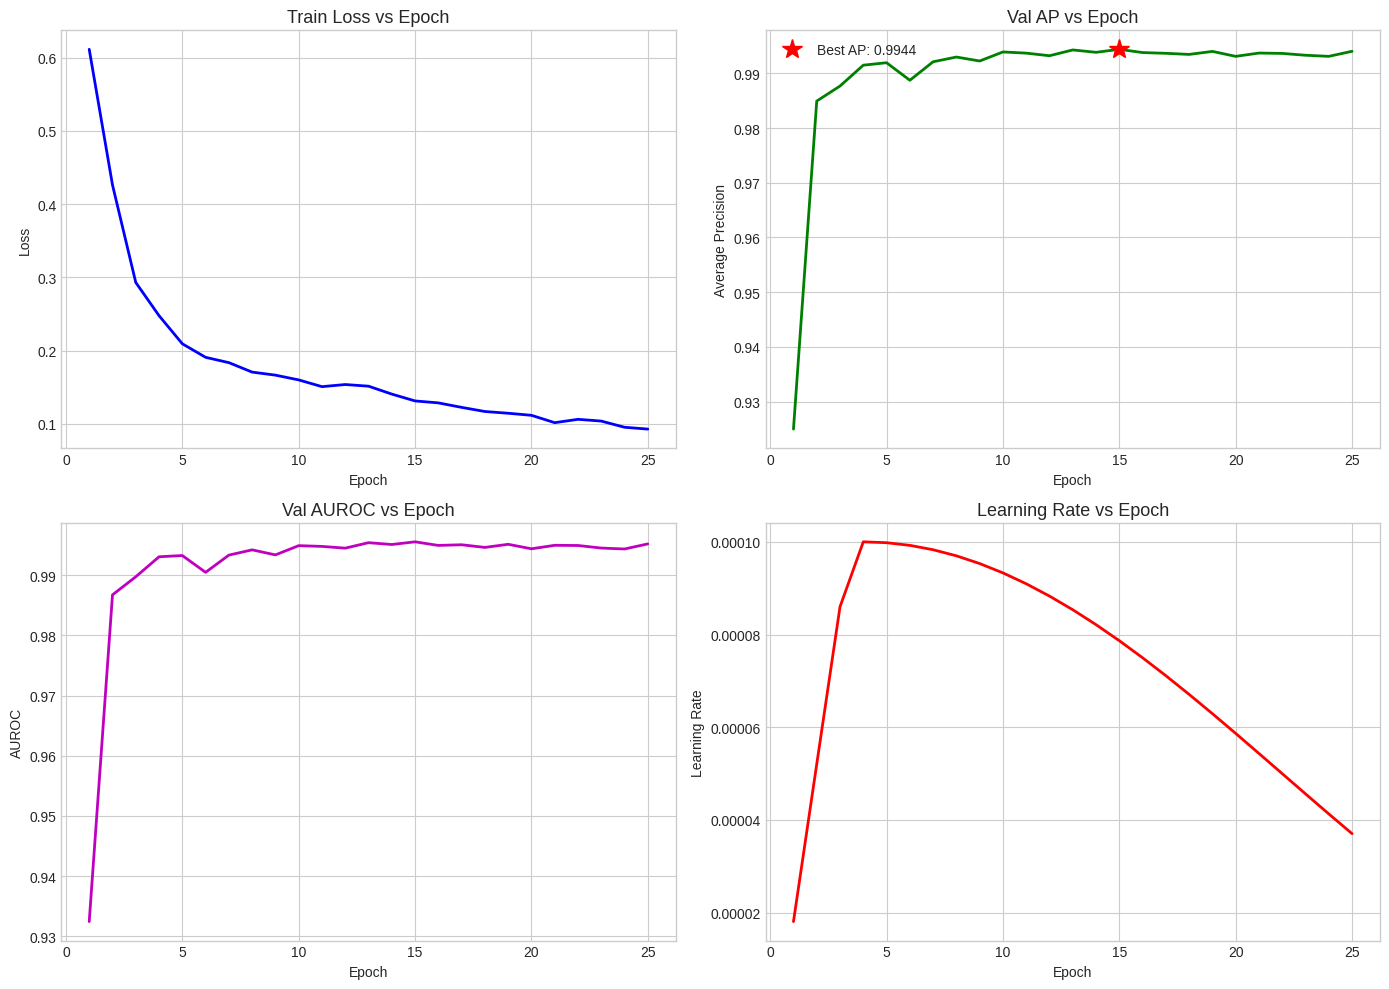

Saved: training_curves.png


In [8]:
# ==========================================
# CELL 5: TRAINING CURVES VISUALIZATION
# ==========================================

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

epochs_range = range(1, len(history['train_loss']) + 1)

# Train Loss
axes[0, 0].plot(epochs_range, history['train_loss'], 'b-', linewidth=2)
axes[0, 0].set_title('Train Loss vs Epoch', fontsize=13)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')

# Val AP
axes[0, 1].plot(epochs_range, history['val_ap'], 'g-', linewidth=2)
best_epoch = np.argmax(history['val_ap']) + 1
axes[0, 1].plot(best_epoch, max(history['val_ap']), 'r*', markersize=15, label=f'Best AP: {max(history["val_ap"]):.4f}')
axes[0, 1].set_title('Val AP vs Epoch', fontsize=13)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Average Precision')
axes[0, 1].legend()

# Val AUROC
axes[1, 0].plot(epochs_range, history['val_auroc'], 'm-', linewidth=2)
axes[1, 0].set_title('Val AUROC vs Epoch', fontsize=13)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('AUROC')

# Learning Rate
axes[1, 1].plot(epochs_range, history['lr'], 'r-', linewidth=2)
axes[1, 1].set_title('Learning Rate vs Epoch', fontsize=13)
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Learning Rate')

plt.tight_layout()
plt.savefig('training_curves.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: training_curves.png")

## Cell 6: Comprehensive Evaluation

Evaluates the best model on the **test set** (not validation). Computes optimal threshold, classification report, and all key metrics.

In [9]:
# ==========================================
# CELL 6: COMPREHENSIVE EVALUATION
# ==========================================

# Load best model
model.load_state_dict(torch.load('wave_swin_gnn_best.pth', map_location=device))
model.eval()

test_labels_list, test_scores_list, test_sources_list = [], [], []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Evaluating on test set"):
        images = images.to(device)
        with torch.amp.autocast('cuda'):
            outputs = model(images)
        test_scores_list.extend(torch.sigmoid(outputs).cpu().numpy().flatten())
        test_labels_list.extend(labels.numpy().flatten())

# Track source for each test sample
test_sources_list = [d['source'] for d in test_data]

test_labels = np.array(test_labels_list)
test_scores = np.array(test_scores_list)

# ---- Optimal threshold (maximize F1) ----
precision_arr, recall_arr, thresholds_arr = precision_recall_curve(test_labels, test_scores)
f1_arr = 2 * (precision_arr[:-1] * recall_arr[:-1]) / (precision_arr[:-1] + recall_arr[:-1] + 1e-8)
optimal_idx = np.argmax(f1_arr)
optimal_threshold = thresholds_arr[optimal_idx]

test_preds = (test_scores >= optimal_threshold).astype(int)

# ---- Metrics ----
acc = accuracy_score(test_labels, test_preds)
prec = precision_score(test_labels, test_preds)
rec = recall_score(test_labels, test_preds)
f1 = f1_score(test_labels, test_preds)
ap = average_precision_score(test_labels, test_scores)
auroc = roc_auc_score(test_labels, test_scores)

print(f"\n{'='*50}")
print(f"TEST SET RESULTS (n={len(test_labels)})")
print(f"{'='*50}")
print(f"Optimal Threshold: {optimal_threshold:.4f}")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"AP:        {ap:.4f}")
print(f"AUROC:     {auroc:.4f}")

# ---- Recall at 85% precision ----
mask_85 = precision_arr >= 0.85
if mask_85.any():
    idx_85 = np.where(mask_85)[0][0]
    print(f"\nAt 85% Precision:")
    print(f"  Threshold: {thresholds_arr[idx_85]:.4f}")
    print(f"  Recall:    {recall_arr[idx_85]:.4f}")

print(f"\n{'='*50}")
print("Classification Report:")
print(f"{'='*50}")
print(classification_report(test_labels, test_preds, target_names=['Non-Fractured', 'Fractured']))

Evaluating on test set:   0%|          | 0/137 [00:00<?, ?it/s]


TEST SET RESULTS (n=2189)
Optimal Threshold: 0.5293
Accuracy:  0.9758
Precision: 0.9771
Recall:    0.9627
F1-Score:  0.9698
AP:        0.9951
AUROC:     0.9961

At 85% Precision:
  Threshold: 0.2532
  Recall:    0.9876

Classification Report:
               precision    recall  f1-score   support

Non-Fractured       0.97      0.98      0.98      1304
    Fractured       0.98      0.96      0.97       885

     accuracy                           0.98      2189
    macro avg       0.98      0.97      0.97      2189
 weighted avg       0.98      0.98      0.98      2189



## Cell 7: Evaluation Plots

6 publication-quality plots: ROC curve, PR curve, confusion matrix, score distribution, PR vs threshold, and per-dataset performance.

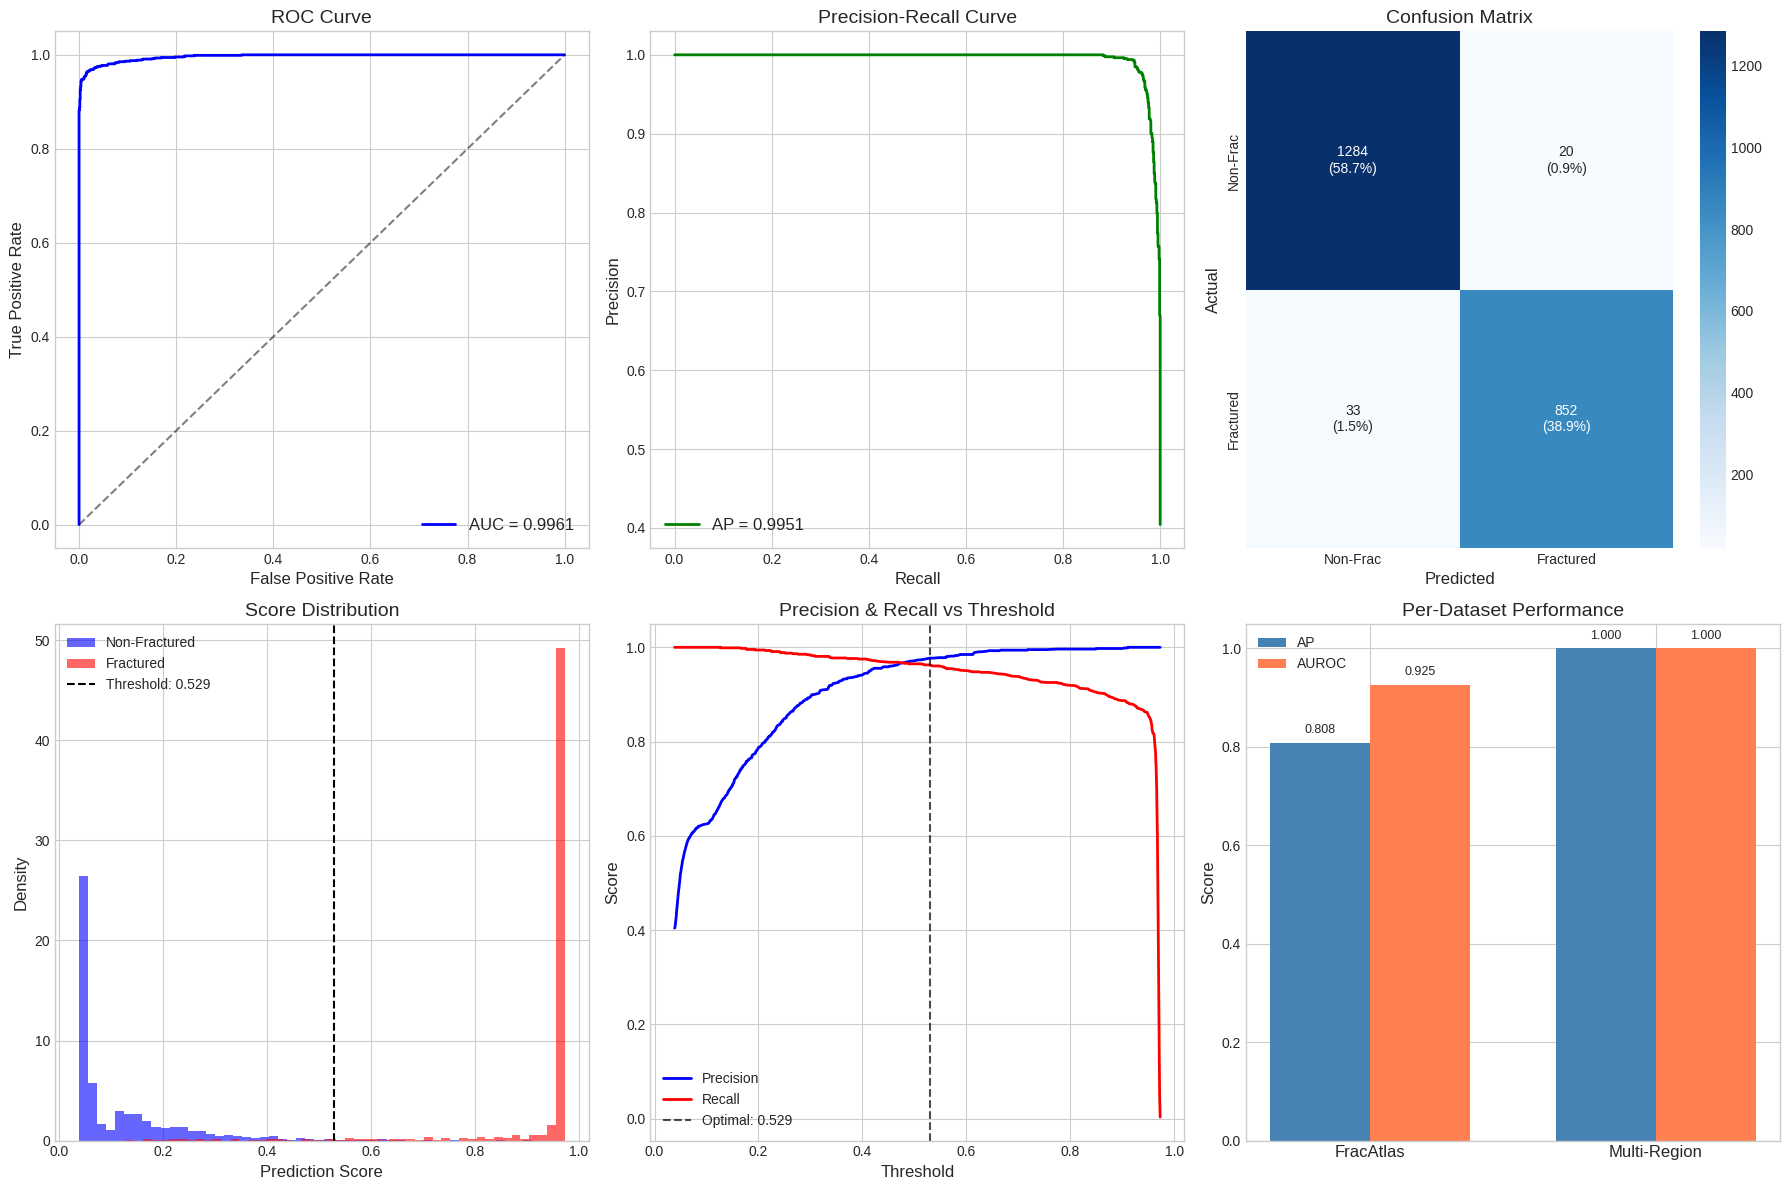

Saved: evaluation_plots.png


In [10]:
# ==========================================
# CELL 7: EVALUATION PLOTS
# ==========================================

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. ROC Curve
fpr, tpr, _ = roc_curve(test_labels, test_scores)
roc_auc_val = auc(fpr, tpr)
axes[0, 0].plot(fpr, tpr, 'b-', linewidth=2, label=f'AUC = {roc_auc_val:.4f}')
axes[0, 0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0, 0].set_xlabel('False Positive Rate', fontsize=12)
axes[0, 0].set_ylabel('True Positive Rate', fontsize=12)
axes[0, 0].set_title('ROC Curve', fontsize=14)
axes[0, 0].legend(fontsize=12)

# 2. Precision-Recall Curve
axes[0, 1].plot(recall_arr, precision_arr, 'g-', linewidth=2, label=f'AP = {ap:.4f}')
axes[0, 1].set_xlabel('Recall', fontsize=12)
axes[0, 1].set_ylabel('Precision', fontsize=12)
axes[0, 1].set_title('Precision-Recall Curve', fontsize=14)
axes[0, 1].legend(fontsize=12)

# 3. Confusion Matrix
cm = confusion_matrix(test_labels, test_preds)
cm_pct = cm.astype('float') / cm.sum() * 100
annot = np.array([[f"{cm[i,j]}\n({cm_pct[i,j]:.1f}%)" for j in range(2)] for i in range(2)])
sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', ax=axes[0, 2],
            xticklabels=['Non-Frac', 'Fractured'], yticklabels=['Non-Frac', 'Fractured'])
axes[0, 2].set_xlabel('Predicted', fontsize=12)
axes[0, 2].set_ylabel('Actual', fontsize=12)
axes[0, 2].set_title('Confusion Matrix', fontsize=14)

# 4. Score Distribution
scores_neg = test_scores[test_labels == 0]
scores_pos = test_scores[test_labels == 1]
axes[1, 0].hist(scores_neg, bins=50, alpha=0.6, color='blue', label='Non-Fractured', density=True)
axes[1, 0].hist(scores_pos, bins=50, alpha=0.6, color='red', label='Fractured', density=True)
axes[1, 0].axvline(optimal_threshold, color='black', linestyle='--', label=f'Threshold: {optimal_threshold:.3f}')
axes[1, 0].set_xlabel('Prediction Score', fontsize=12)
axes[1, 0].set_ylabel('Density', fontsize=12)
axes[1, 0].set_title('Score Distribution', fontsize=14)
axes[1, 0].legend(fontsize=10)

# 5. Precision-Recall vs Threshold
axes[1, 1].plot(thresholds_arr, precision_arr[:-1], 'b-', linewidth=2, label='Precision')
axes[1, 1].plot(thresholds_arr, recall_arr[:-1], 'r-', linewidth=2, label='Recall')
axes[1, 1].axvline(optimal_threshold, color='black', linestyle='--', alpha=0.7, label=f'Optimal: {optimal_threshold:.3f}')
axes[1, 1].set_xlabel('Threshold', fontsize=12)
axes[1, 1].set_ylabel('Score', fontsize=12)
axes[1, 1].set_title('Precision & Recall vs Threshold', fontsize=14)
axes[1, 1].legend(fontsize=10)

# 6. Per-Dataset Performance
test_sources = np.array(test_sources_list)
dataset_names = ['FracAtlas', 'Multi-Region']
dataset_keys = ['fracatlas', 'multiregion']
dataset_aps = []
dataset_aurocs = []
for key in dataset_keys:
    mask = test_sources == key
    if mask.sum() > 0 and len(np.unique(test_labels[mask])) > 1:
        dataset_aps.append(average_precision_score(test_labels[mask], test_scores[mask]))
        dataset_aurocs.append(roc_auc_score(test_labels[mask], test_scores[mask]))
    else:
        dataset_aps.append(0)
        dataset_aurocs.append(0)

x_pos = np.arange(len(dataset_names))
width = 0.35
axes[1, 2].bar(x_pos - width/2, dataset_aps, width, label='AP', color='steelblue')
axes[1, 2].bar(x_pos + width/2, dataset_aurocs, width, label='AUROC', color='coral')
axes[1, 2].set_xticks(x_pos)
axes[1, 2].set_xticklabels(dataset_names, fontsize=12)
axes[1, 2].set_ylabel('Score', fontsize=12)
axes[1, 2].set_title('Per-Dataset Performance', fontsize=14)
axes[1, 2].legend(fontsize=10)
axes[1, 2].set_ylim(0, 1.05)
for i, (a, r) in enumerate(zip(dataset_aps, dataset_aurocs)):
    axes[1, 2].text(i - width/2, a + 0.02, f'{a:.3f}', ha='center', fontsize=9)
    axes[1, 2].text(i + width/2, r + 0.02, f'{r:.3f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('evaluation_plots.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: evaluation_plots.png")

## Cell 8: Ablation Study

Trains and evaluates 4 model variants (20 epochs each) to quantify each component's contribution:
1. Swin-Only
2. Swin + DWT
3. Swin + GNN
4. Wave-Swin-GNN (Full)


Training: Swin-Only


Epoch 1/20:   0%|          | 0/639 [00:00<?, ?it/s]

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


  Epoch 1/20 | Val AP: 0.9309


Epoch 2/20:   0%|          | 0/639 [00:00<?, ?it/s]

...

libpng warning: bKGD: invalid
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: bKGD: invalid
libpng warning: bKGD: invalid
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


  Epoch 19/20 | Val AP: 0.9934


Epoch 20/20:   0%|          | 0/639 [00:00<?, ?it/s]

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: bKGD: invalid
libpng warning: bKGD: invalid
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


  Epoch 20/20 | Val AP: 0.9935

ABLATION STUDY RESULTS
               Model  Accuracy  Precision  Recall     F1     AP  AUROC
           Swin-Only    0.9762     0.9793  0.9616 0.9704 0.9954 0.9963
            Swin+DWT    0.9753     0.9848  0.9537 0.9690 0.9949 0.9959
            Swin+GNN    0.9753     0.9906  0.9480 0.9688 0.9954 0.9963
Wave-Swin-GNN (Full)    0.9758     0.9771  0.9627 0.9698 0.9951 0.9961


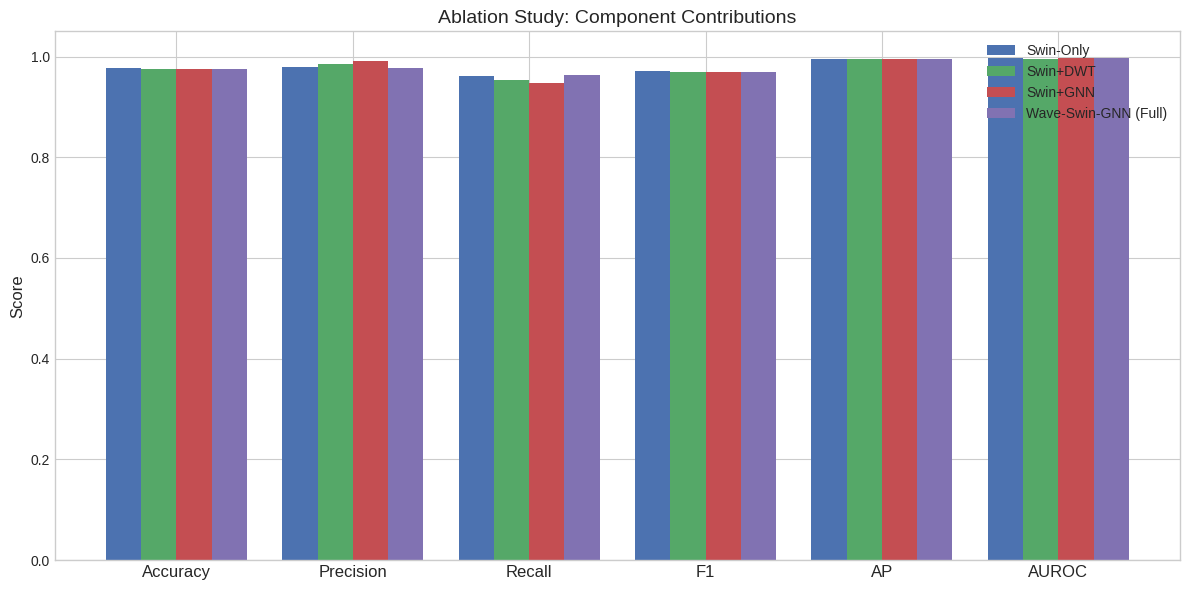

Saved: ablation_results.png


In [11]:
# ==========================================
# CELL 8: ABLATION STUDY
# ==========================================

class SwinOnly(nn.Module):
    """Variant 1: SwinV2-Tiny -> GlobalPool -> Classifier"""
    def __init__(self):
        super().__init__()
        self.swin = timm.create_model('swinv2_tiny_window8_256', pretrained=True, num_classes=0, global_pool='')
        self.feature_dim = self.swin.num_features
        for name, param in self.swin.named_parameters():
            if ('layers.0' in name or 'layers.1' in name or 'layers.2' in name) and 'norm' not in name:
                param.requires_grad = False
        self.classifier = nn.Sequential(
            nn.Linear(self.feature_dim, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(128, 1)
        )
    
    def forward(self, x):
        B = x.shape[0]
        feat = self.swin(x)
        if feat.dim() == 4:
            feat = feat.reshape(B, -1, self.feature_dim)
        feat = feat.mean(dim=1)
        return self.classifier(feat)


class SwinDWT(nn.Module):
    """Variant 2: SwinV2-Tiny + Wavelet dual-path -> Classifier (no GNN)"""
    def __init__(self):
        super().__init__()
        self.dwt = TorchDWT()
        self.wavelet_adapter = WaveletAdapter(out_dim=256)
        self.swin = timm.create_model('swinv2_tiny_window8_256', pretrained=True, num_classes=0, global_pool='')
        self.feature_dim = self.swin.num_features
        for name, param in self.swin.named_parameters():
            if ('layers.0' in name or 'layers.1' in name or 'layers.2' in name) and 'norm' not in name:
                param.requires_grad = False
        self.swin_proj = nn.Linear(self.feature_dim, 256)
        self.classifier = nn.Sequential(
            nn.Linear(512, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(128, 1)
        )
    
    def forward(self, x):
        B = x.shape[0]
        wavelet_feat = self.wavelet_adapter(self.dwt(x))
        feat = self.swin(x)
        if feat.dim() == 4:
            feat = feat.reshape(B, -1, self.feature_dim)
        swin_feat = self.swin_proj(feat.mean(dim=1))
        return self.classifier(torch.cat([wavelet_feat, swin_feat], dim=1))


class SwinGNN(nn.Module):
    """Variant 3: SwinV2-Tiny -> GNN -> Classifier (no wavelet)"""
    def __init__(self, k=6):
        super().__init__()
        self.k = k
        self.swin = timm.create_model('swinv2_tiny_window8_256', pretrained=True, num_classes=0, global_pool='')
        self.feature_dim = self.swin.num_features
        for name, param in self.swin.named_parameters():
            if ('layers.0' in name or 'layers.1' in name or 'layers.2' in name) and 'norm' not in name:
                param.requires_grad = False
        self.gnn1 = GATv2Conv(self.feature_dim, 256, heads=4, concat=True, dropout=0.2)
        self.gnn_norm1 = nn.LayerNorm(1024)
        self.gnn2 = GATv2Conv(1024, 256, heads=1, concat=False, dropout=0.2)
        self.gnn_norm2 = nn.LayerNorm(256)
        self.swin_proj = nn.Linear(self.feature_dim, 256)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(128, 1)
        )
    
    def build_knn_graph(self, num_nodes, batch_size, device):
        N = num_nodes // batch_size
        side = int(np.sqrt(N))
        if side * side < N:
            side += 1
        coords = torch.stack(
            torch.meshgrid(torch.arange(side), torch.arange(side), indexing='ij'), dim=-1
        ).float().reshape(-1, 2)[:N].to(device)
        dist = torch.cdist(coords, coords)
        _, topk = torch.topk(dist, k=min(self.k, N), largest=False)
        edge_indices = []
        for b in range(batch_size):
            offset = b * N
            src = torch.arange(N, device=device).view(-1, 1).expand(-1, min(self.k, N)).reshape(-1) + offset
            dst = topk.reshape(-1) + offset
            edge_indices.append(torch.stack([src, dst], dim=0))
        return torch.cat(edge_indices, dim=1)
    
    def forward(self, x):
        B = x.shape[0]
        feat = self.swin(x)
        if feat.dim() == 4:
            feat = feat.reshape(B, -1, self.feature_dim)
        N = feat.shape[1]
        swin_residual = self.swin_proj(feat.mean(dim=1))
        x_flat = feat.reshape(-1, self.feature_dim)
        edge_index = self.build_knn_graph(x_flat.shape[0], B, x_flat.device)
        x_gnn = self.gnn1(x_flat, edge_index)
        x_gnn = self.gnn_norm1(x_gnn).relu()
        x_gnn = self.gnn2(x_gnn, edge_index)
        x_gnn = self.gnn_norm2(x_gnn).relu()
        gnn_pooled = x_gnn.reshape(B, N, -1).mean(dim=1)
        return self.classifier(gnn_pooled + swin_residual)


def train_ablation_variant(variant_model, variant_name, epochs=20):
    """Train and evaluate an ablation variant."""
    print(f"\n{'='*50}")
    print(f"Training: {variant_name}")
    print(f"{'='*50}")
    
    variant_model = variant_model.to(device)
    opt = optim.AdamW(filter(lambda p: p.requires_grad, variant_model.parameters()), lr=2e-5, weight_decay=0.05)
    sched = optim.lr_scheduler.OneCycleLR(
        opt, max_lr=1e-4,
        steps_per_epoch=len(train_loader) // ACCUMULATION_STEPS,
        epochs=epochs, pct_start=0.1
    )
    sc = torch.amp.GradScaler('cuda')
    crit = FocalLoss(alpha=0.75, gamma=2.0)
    best_ap_v = 0.0
    
    for epoch in range(epochs):
        variant_model.train()
        opt.zero_grad()
        for i, (images, labels) in enumerate(tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=False)):
            images = images.to(device)
            labels = labels.to(device).unsqueeze(1)
            with torch.amp.autocast('cuda'):
                outputs = variant_model(images)
                loss = crit(outputs, labels) / ACCUMULATION_STEPS
            sc.scale(loss).backward()
            if (i + 1) % ACCUMULATION_STEPS == 0:
                sc.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(variant_model.parameters(), max_norm=1.0)
                sc.step(opt)
                sc.update()
                opt.zero_grad()
                sched.step()
        
        # Validation
        variant_model.eval()
        vl, vs = [], []
        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                with torch.amp.autocast('cuda'):
                    outputs = variant_model(images)
                vs.extend(torch.sigmoid(outputs).cpu().numpy().flatten())
                vl.extend(labels.numpy().flatten())
        v_ap = average_precision_score(vl, vs)
        if v_ap > best_ap_v:
            best_ap_v = v_ap
            torch.save(variant_model.state_dict(), f'ablation_{variant_name.lower().replace(" ", "_")}.pth')
        print(f"  Epoch {epoch+1}/{epochs} | Val AP: {v_ap:.4f}")
    
    # Evaluate on test set
    variant_model.load_state_dict(torch.load(f'ablation_{variant_name.lower().replace(" ", "_")}.pth', map_location=device))
    variant_model.eval()
    tl, ts = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            with torch.amp.autocast('cuda'):
                outputs = variant_model(images)
            ts.extend(torch.sigmoid(outputs).cpu().numpy().flatten())
            tl.extend(labels.numpy().flatten())
    
    tl, ts = np.array(tl), np.array(ts)
    p_arr, r_arr, t_arr = precision_recall_curve(tl, ts)
    f1_arr_v = 2 * (p_arr[:-1] * r_arr[:-1]) / (p_arr[:-1] + r_arr[:-1] + 1e-8)
    opt_t = t_arr[np.argmax(f1_arr_v)]
    tp = (ts >= opt_t).astype(int)
    
    results = {
        'Model': variant_name,
        'Accuracy': accuracy_score(tl, tp),
        'Precision': precision_score(tl, tp),
        'Recall': recall_score(tl, tp),
        'F1': f1_score(tl, tp),
        'AP': average_precision_score(tl, ts),
        'AUROC': roc_auc_score(tl, ts),
    }
    
    # Cleanup
    del variant_model, opt, sc, sched
    gc.collect()
    torch.cuda.empty_cache()
    
    return results


# Run ablation variants
ablation_results = []

# Variant 1: Swin-Only
ablation_results.append(train_ablation_variant(SwinOnly(), 'Swin-Only'))

# Variant 2: Swin + DWT
ablation_results.append(train_ablation_variant(SwinDWT(), 'Swin+DWT'))

# Variant 3: Swin + GNN
ablation_results.append(train_ablation_variant(SwinGNN(), 'Swin+GNN'))

# Variant 4: Full model (use already-trained best model)
model.load_state_dict(torch.load('wave_swin_gnn_best.pth', map_location=device))
model.eval()
full_tl, full_ts = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        with torch.amp.autocast('cuda'):
            outputs = model(images)
        full_ts.extend(torch.sigmoid(outputs).cpu().numpy().flatten())
        full_tl.extend(labels.numpy().flatten())
full_tl, full_ts = np.array(full_tl), np.array(full_ts)
p_a, r_a, t_a = precision_recall_curve(full_tl, full_ts)
f1_a = 2 * (p_a[:-1] * r_a[:-1]) / (p_a[:-1] + r_a[:-1] + 1e-8)
opt_t_full = t_a[np.argmax(f1_a)]
tp_full = (full_ts >= opt_t_full).astype(int)
ablation_results.append({
    'Model': 'Wave-Swin-GNN (Full)',
    'Accuracy': accuracy_score(full_tl, tp_full),
    'Precision': precision_score(full_tl, tp_full),
    'Recall': recall_score(full_tl, tp_full),
    'F1': f1_score(full_tl, tp_full),
    'AP': average_precision_score(full_tl, full_ts),
    'AUROC': roc_auc_score(full_tl, full_ts),
})

# Display results table
ablation_df = pd.DataFrame(ablation_results)
print("\n" + "="*80)
print("ABLATION STUDY RESULTS")
print("="*80)
print(ablation_df.to_string(index=False, float_format='%.4f'))

# Plot
fig, ax = plt.subplots(figsize=(12, 6))
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'AP', 'AUROC']
x = np.arange(len(metrics))
width = 0.2
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']

for i, row in ablation_df.iterrows():
    values = [row[m] for m in metrics]
    ax.bar(x + i * width, values, width, label=row['Model'], color=colors[i])

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics, fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Ablation Study: Component Contributions', fontsize=14)
ax.legend(fontsize=10)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig('ablation_results.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: ablation_results.png")

## Cell 9: Grad-CAM Visualization

Implements Grad-CAM for the Swin backbone's last layer to visualize where the model focuses its attention. Shows 4 correct and 4 incorrect predictions.

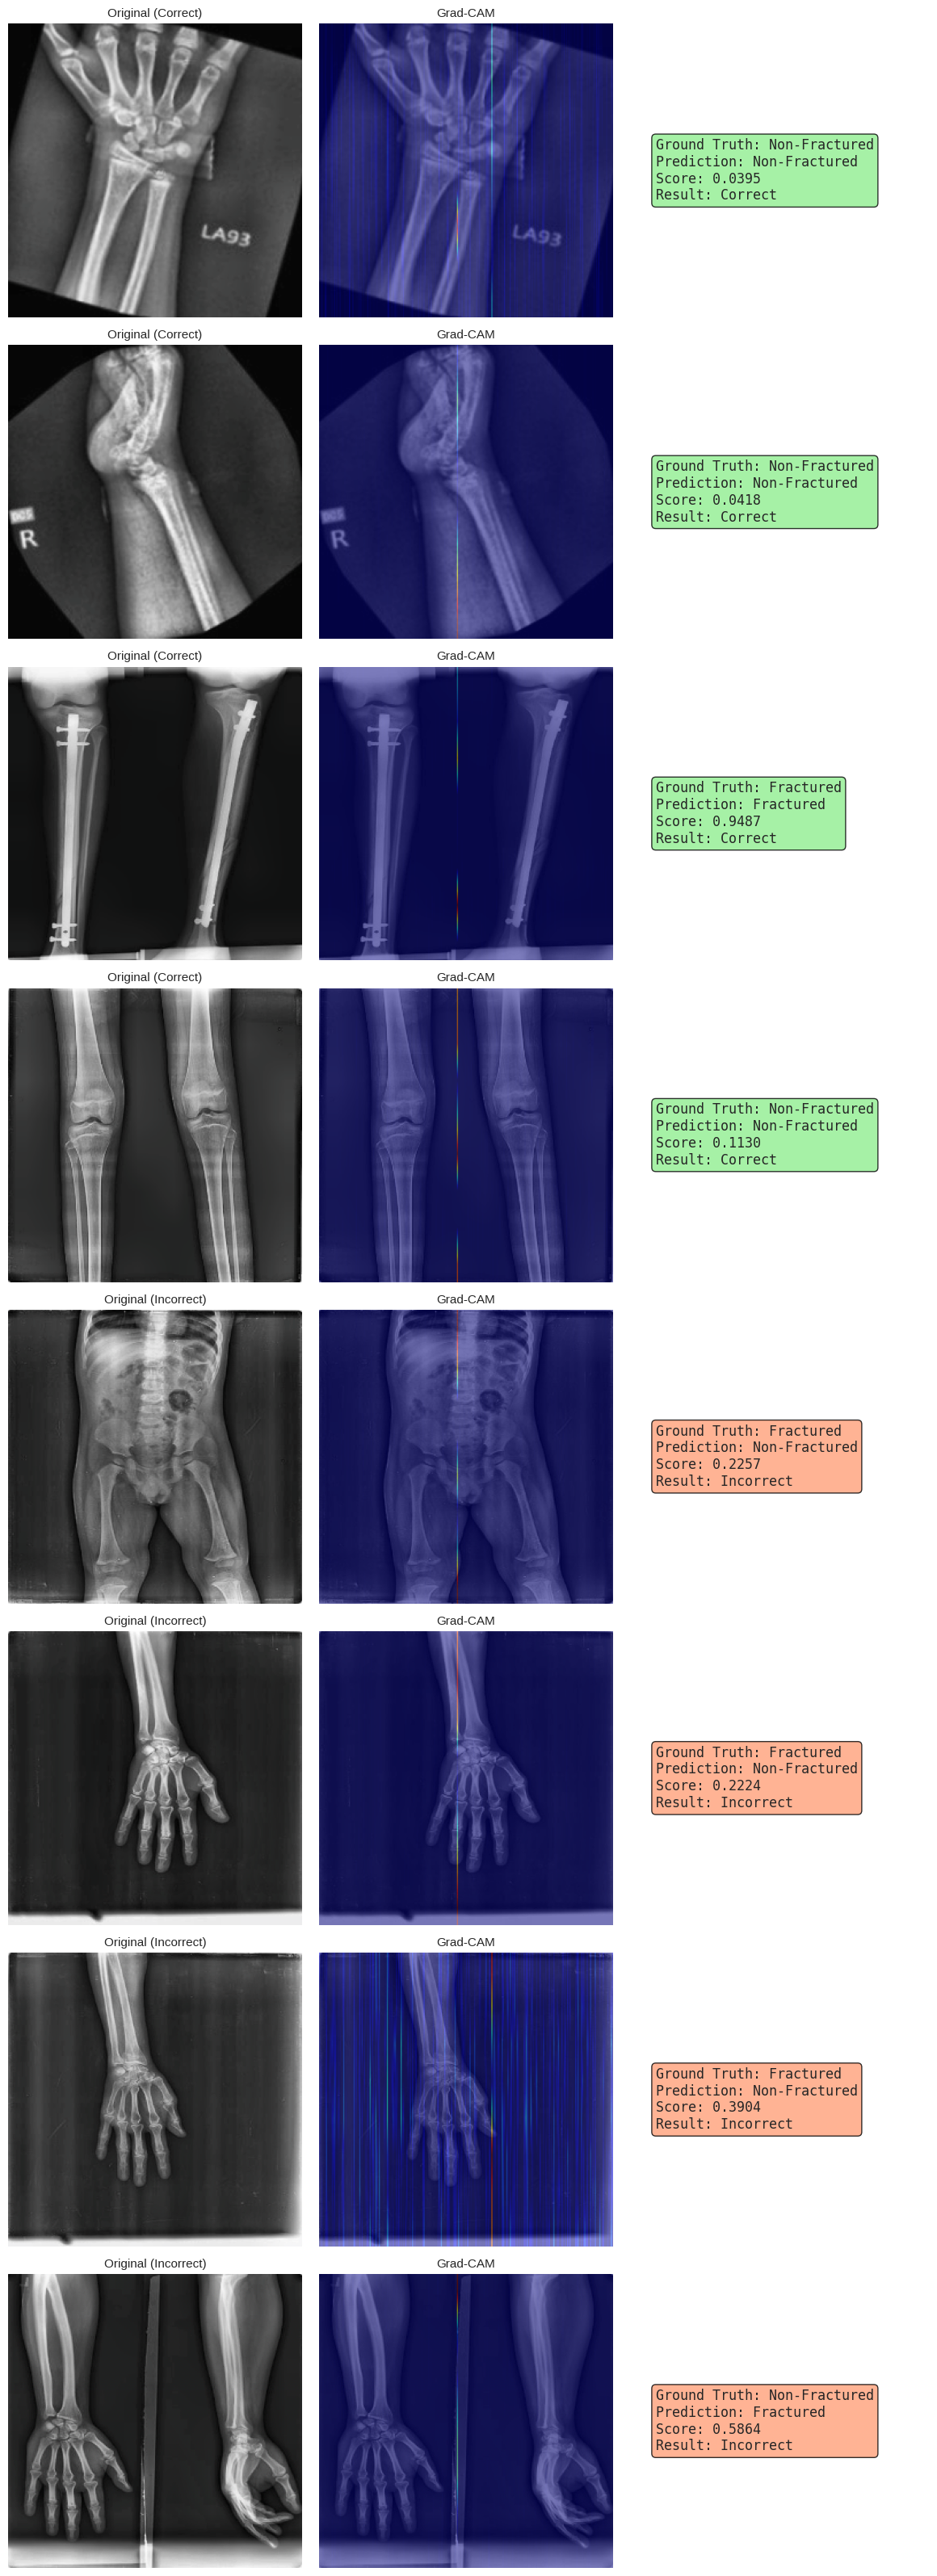

Saved: gradcam_results.png


In [12]:
# ==========================================
# CELL 9: GRAD-CAM VISUALIZATION
# ==========================================

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        target_layer.register_forward_hook(self._forward_hook)
        target_layer.register_full_backward_hook(self._backward_hook)
    
    def _forward_hook(self, module, input, output):
        self.activations = output.detach()
    
    def _backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
    
    def generate(self, input_tensor, target_class=None):
        self.model.eval()
        output = self.model(input_tensor)
        
        self.model.zero_grad()
        if target_class is None:
            target = output
        else:
            target = output[:, target_class] if output.dim() > 1 else output
        target.backward(torch.ones_like(target))
        
        gradients = self.gradients
        activations = self.activations
        
        if gradients.dim() == 3:
            # (B, N, C) -> spatial reshape
            B, N, C = gradients.shape
            side = int(np.sqrt(N))
            gradients = gradients[:, :side*side, :].reshape(B, side, side, C).permute(0, 3, 1, 2)
            activations = activations[:, :side*side, :].reshape(B, side, side, C).permute(0, 3, 1, 2)
        
        weights = gradients.mean(dim=[2, 3], keepdim=True)
        cam = (weights * activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
        cam = cam.squeeze(1)
        
        # Normalize per sample
        for i in range(cam.shape[0]):
            cam_min, cam_max = cam[i].min(), cam[i].max()
            if cam_max - cam_min > 0:
                cam[i] = (cam[i] - cam_min) / (cam_max - cam_min)
        
        return cam.cpu().numpy()


# Get the last Swin layer for Grad-CAM
model.load_state_dict(torch.load('wave_swin_gnn_best.pth', map_location=device))
model.eval()
target_layer = model.swin.layers[-1]
grad_cam = GradCAM(model, target_layer)

# Collect predictions on test set
correct_samples = []  # (image, label, score, cam)
incorrect_samples = []

MEAN = np.array([0.485, 0.456, 0.406])
STD = np.array([0.229, 0.224, 0.225])

for images, labels in test_loader:
    images_gpu = images.to(device)
    images_gpu.requires_grad_(True)
    
    with torch.amp.autocast('cuda', enabled=False):
        cams = grad_cam.generate(images_gpu.float())
    
    with torch.no_grad():
        with torch.amp.autocast('cuda'):
            outputs = model(images_gpu)
        scores = torch.sigmoid(outputs).cpu().numpy().flatten()
    
    for i in range(len(labels)):
        pred = int(scores[i] >= optimal_threshold)
        gt = int(labels[i].item())
        img_np = images[i].numpy().transpose(1, 2, 0)
        img_np = (img_np * STD + MEAN).clip(0, 1)
        
        entry = (img_np, gt, scores[i], cams[i])
        if pred == gt and len(correct_samples) < 4:
            correct_samples.append(entry)
        elif pred != gt and len(incorrect_samples) < 4:
            incorrect_samples.append(entry)
    
    if len(correct_samples) >= 4 and len(incorrect_samples) >= 4:
        break

# Plot Grad-CAM grid
all_samples = correct_samples[:4] + incorrect_samples[:4]
sample_labels_text = ['Correct'] * min(4, len(correct_samples)) + ['Incorrect'] * min(4, len(incorrect_samples))

n_samples = len(all_samples)
fig, axes = plt.subplots(n_samples, 3, figsize=(12, 4 * n_samples))
if n_samples == 1:
    axes = axes[np.newaxis, :]

for i, (img, gt, score, cam) in enumerate(all_samples):
    pred_label = 'Fractured' if score >= optimal_threshold else 'Non-Fractured'
    gt_label = 'Fractured' if gt == 1 else 'Non-Fractured'
    status = sample_labels_text[i]
    
    # Original
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f'Original ({status})', fontsize=11)
    axes[i, 0].axis('off')
    
    # Grad-CAM overlay
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0
    overlay = 0.5 * img + 0.5 * heatmap
    overlay = overlay.clip(0, 1)
    axes[i, 1].imshow(overlay)
    axes[i, 1].set_title('Grad-CAM', fontsize=11)
    axes[i, 1].axis('off')
    
    # Info
    axes[i, 2].axis('off')
    info_text = f"Ground Truth: {gt_label}\nPrediction: {pred_label}\nScore: {score:.4f}\nResult: {status}"
    axes[i, 2].text(0.1, 0.5, info_text, fontsize=12, verticalalignment='center',
                    fontfamily='monospace',
                    bbox=dict(boxstyle='round', facecolor='lightgreen' if status == 'Correct' else 'lightsalmon', alpha=0.8))

plt.tight_layout()
plt.savefig('gradcam_results.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: gradcam_results.png")

## Cell 10: Model Summary & Export

In [13]:
# ==========================================
# CELL 10: MODEL SUMMARY & EXPORT
# ==========================================

print("="*60)
print("WAVE-SWIN-GNN — FINAL SUMMARY")
print("="*60)

print(f"\n--- Architecture ---")
print(f"  Backbone: SwinV2-Tiny (window8_256)")
print(f"  Wavelet: GPU-Native Haar DWT (dual-path)")
print(f"  GNN: GATv2Conv (k=6, heads=4 -> heads=1) with residual")
print(f"  Classifier: Linear(512->128) -> LayerNorm -> GELU -> Dropout(0.3) -> Linear(128->1)")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")

print(f"\n--- Dataset ---")
print(f"  Combined: FracAtlas + Bone Fracture Multi-Region")
print(f"  Total images: {len(all_data)}")
print(f"  Train: {len(train_data)} | Val: {len(val_data)} | Test: {len(test_data)}")
print(f"  Resolution: {IMG_SIZE}x{IMG_SIZE}")

print(f"\n--- Training ---")
print(f"  Epochs: {len(history['train_loss'])} (of {EPOCHS} max)")
print(f"  Training time: {training_time/60:.1f} minutes")
print(f"  Loss: Focal (alpha=0.75, gamma=2.0)")
print(f"  Optimizer: AdamW (lr=2e-5, wd=0.05)")
print(f"  Scheduler: OneCycleLR (max_lr=1e-4)")
print(f"  Effective batch size: {8 * ACCUMULATION_STEPS}")

print(f"\n--- Test Results ---")
print(f"  Accuracy:  {acc:.4f}")
print(f"  Precision: {prec:.4f}")
print(f"  Recall:    {rec:.4f}")
print(f"  F1-Score:  {f1:.4f}")
print(f"  AP:        {ap:.4f}")
print(f"  AUROC:     {auroc:.4f}")

# Save final model
torch.save(model.state_dict(), 'wave_swin_gnn_best.pth')
print(f"\nModel saved: wave_swin_gnn_best.pth")
print("="*60)

WAVE-SWIN-GNN — FINAL SUMMARY

--- Architecture ---
  Backbone: SwinV2-Tiny (window8_256)
  Wavelet: GPU-Native Haar DWT (dual-path)
  GNN: GATv2Conv (k=6, heads=4 -> heads=1) with residual
  Classifier: Linear(512->128) -> LayerNorm -> GELU -> Dropout(0.3) -> Linear(128->1)
  Total parameters: 30,059,947
  Trainable parameters: 17,883,985

--- Dataset ---
  Combined: FracAtlas + Bone Fracture Multi-Region
  Total images: 14587
  Train: 10210 | Val: 2188 | Test: 2189
  Resolution: 256x256

--- Training ---
  Epochs: 25 (of 40 max)
  Training time: 36.8 minutes
  Loss: Focal (alpha=0.75, gamma=2.0)
  Optimizer: AdamW (lr=2e-5, wd=0.05)
  Scheduler: OneCycleLR (max_lr=1e-4)
  Effective batch size: 16

--- Test Results ---
  Accuracy:  0.9758
  Precision: 0.9771
  Recall:    0.9627
  F1-Score:  0.9698
  AP:        0.9951
  AUROC:     0.9961

Model saved: wave_swin_gnn_best.pth
